# Sesión 1 · La imagen como arreglo numérico
**Unidad 1. Introducción al procesamiento digital de imágenes** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S1_Imagen_digital_como_dato.ipynb)

**Objetivo de la sesión.** Manipular imágenes como arreglos NumPy y evitar los errores clásicos de color, tipo de dato y compresión.

**Clase síncrona:** jueves 14 de enero de 2027, de 11:00 a 13:00 hrs. · **Sesiones opcionales de la unidad** (12:00 a 13:00 hrs.): jueves 21 de enero (dudas de la actividad 1A); jueves 28 de enero (retroalimentación de 1A y defensas orales).

**Agenda (120 min)**
1. Bienvenida, encuadre del curso y reglas de uso de IA y defensa oral (20 min)
2. La imagen como arreglo: muestreo y cuantización (25 min)
3. Espacios de color y la trampa BGR (20 min)
4. Formatos, compresión y aritmética con saturación (20 min)
5. Caso: las imágenes como conjunto de datos (15 min)
6. Presentación de la actividad 1A y dudas (20 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **1A**.

## 0. Preparación del entorno
Importamos las bibliotecas y definimos `mostrar()`, una función auxiliar para ver varias imágenes a la vez.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


## 1. Una imagen es una matriz de números
Una imagen digital en escala de grises es una función discreta $f(x, y)$ que asigna a cada píxel un **nivel de intensidad**. En Python la representamos como un arreglo NumPy de forma `(alto, ancho)`; si es a color, `(alto, ancho, canales)`.

Usaremos imágenes incluidas en `scikit-image` para que el cuaderno sea reproducible sin descargar nada.

In [2]:
img = data.camera()              # fotografía clásica en escala de grises
print("Tipo de objeto :", type(img))
print("Forma (alto, ancho):", img.shape)
print("Tipo de dato   :", img.dtype)
print("Mínimo / máximo:", img.min(), "/", img.max())
print("Media          :", round(img.mean(), 2))
print("Memoria (KB)   :", img.nbytes / 1024)

Tipo de objeto : <class 'numpy.ndarray'>
Forma (alto, ancho): (512, 512)
Tipo de dato   : uint8
Mínimo / máximo: 0 / 255
Media          : 129.06
Memoria (KB)   : 256.0


Veamos la imagen completa y, a su lado, un recorte de 12 × 12 píxeles con su valor numérico. **Esto es literalmente lo que "ve" la computadora.**

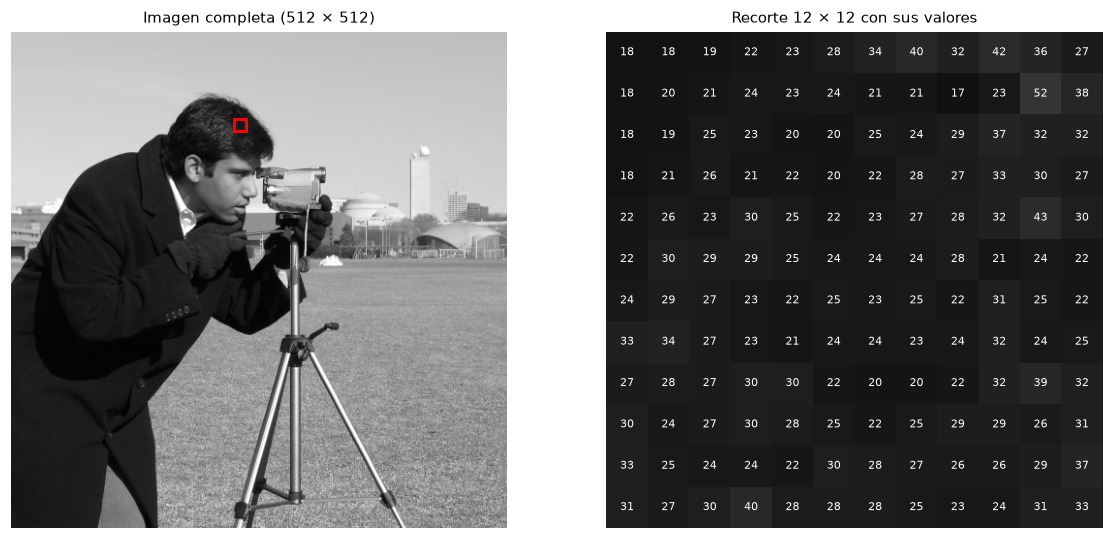

In [3]:
r0, c0 = 90, 230                          # esquina del recorte (fila, columna)
parche = img[r0:r0+12, c0:c0+12]

fig, axs = plt.subplots(1, 2, figsize=(11, 5))
axs[0].imshow(img, cmap="gray"); axs[0].set_title("Imagen completa (512 × 512)")
axs[0].add_patch(plt.Rectangle((c0, r0), 12, 12, edgecolor="red", facecolor="none", lw=2))
axs[1].imshow(parche, cmap="gray", vmin=0, vmax=255); axs[1].set_title("Recorte 12 × 12 con sus valores")
for i in range(12):
    for j in range(12):
        v = parche[i, j]
        axs[1].text(j, i, v, ha="center", va="center", fontsize=7, color="white" if v < 128 else "black")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

### Indexación: filas primero, columnas después
- `img[fila, columna]` → un píxel. El origen `(0, 0)` está **arriba a la izquierda**.
- `img[a:b, c:d]` → una región de interés (ROI). Es una *vista*, no una copia: si la modificas, modificas el original. Usa `.copy()` cuando lo necesites.

Píxel (100, 250): 25


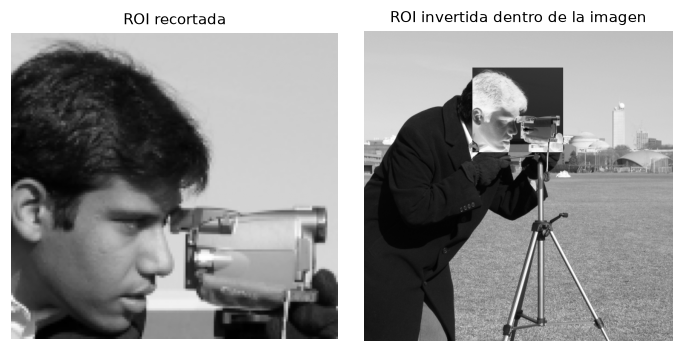

In [4]:
print("Píxel (100, 250):", img[100, 250])
roi = img[60:200, 180:330].copy()
roi_inv = 255 - roi                        # negativo de la región
compuesta = img.copy()
compuesta[60:200, 180:330] = roi_inv
mostrar([roi, compuesta], ["ROI recortada", "ROI invertida dentro de la imagen"])

## 2. Formación de la imagen: muestreo y cuantización
Al digitalizar una escena continua tomamos dos decisiones:
- **Muestreo** (resolución espacial): cuántos píxeles usamos.
- **Cuantización** (resolución de intensidad): cuántos niveles de gris por píxel. Con $k$ bits hay $2^k$ niveles.

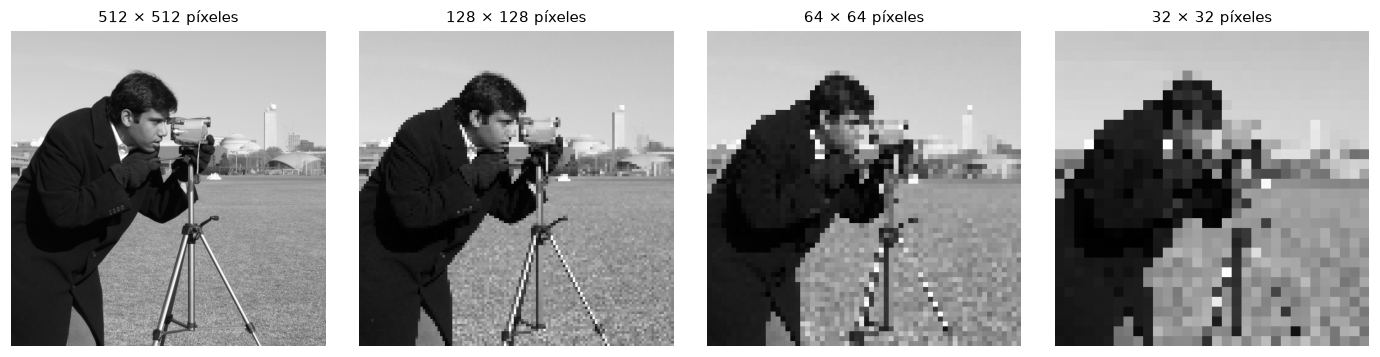

In [5]:
factores = [1, 4, 8, 16]
muestreadas = []
for f in factores:
    peq = img[::f, ::f]                                         # tomar 1 de cada f píxeles
    muestreadas.append(cv2.resize(peq, img.shape[::-1], interpolation=cv2.INTER_NEAREST))
mostrar(muestreadas, [f"{512//f} × {512//f} píxeles" for f in factores])

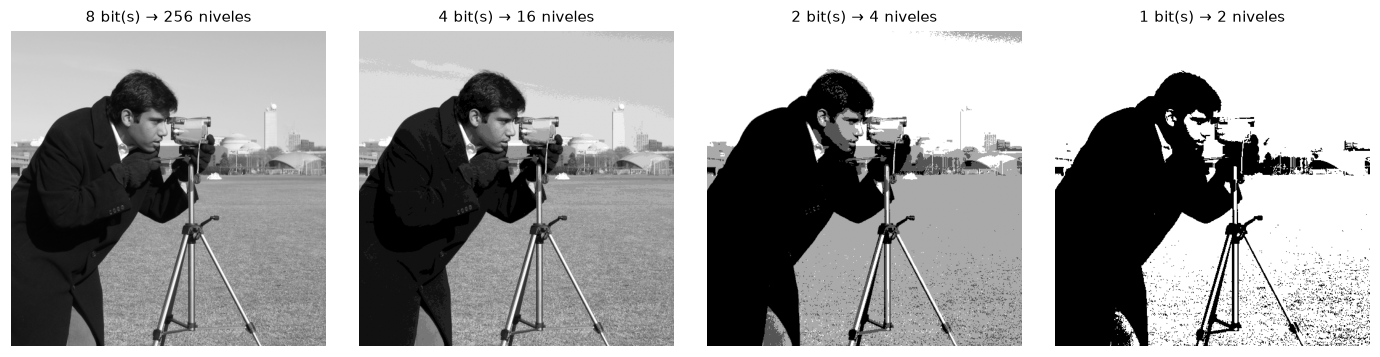

In [6]:
def cuantizar(im, bits):
    niveles = 2 ** bits
    paso = 256 // niveles
    return (im // paso) * paso + paso // 2

bits = [8, 4, 2, 1]
mostrar([cuantizar(img, b) for b in bits], [f"{b} bit(s) → {2**b} niveles" for b in bits])

💬 **Discusión.** En un sistema de inspección de piezas, ¿qué pierdes primero al bajar la resolución: la capacidad de *detectar* la pieza o la de *medir* un defecto pequeño? ¿Y al bajar los niveles de gris?

## 3. Color: canales, RGB, BGR y HSV
Una imagen a color tiene 3 canales. `scikit-image` y `matplotlib` usan el orden **RGB**; **OpenCV lee y escribe en BGR**. Confundirlos es el error #1 en aplicaciones de visión.

Forma: (512, 512, 3) | tipo: uint8


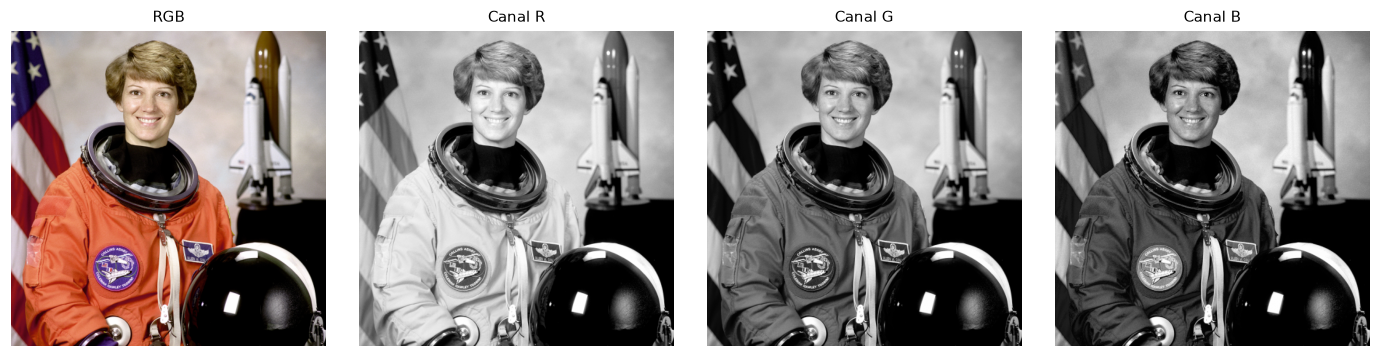

In [7]:
rgb = data.astronaut()
print("Forma:", rgb.shape, "| tipo:", rgb.dtype)
R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
mostrar([rgb, R, G, B], ["RGB", "Canal R", "Canal G", "Canal B"])

### La trampa BGR
Guardamos con OpenCV (que espera BGR) y volvemos a leer. Observa qué pasa si mostramos sin convertir.

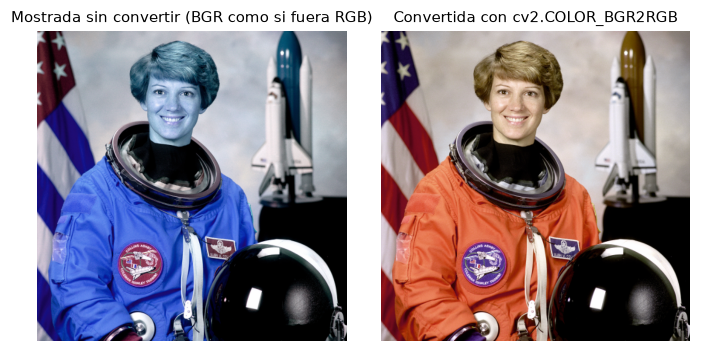

In [8]:
cv2.imwrite("astronauta.png", cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))   # forma correcta de guardar
leida = cv2.imread("astronauta.png")                                  # OpenCV devuelve BGR
mostrar([leida, cv2.cvtColor(leida, cv2.COLOR_BGR2RGB)],
        ["Mostrada sin convertir (BGR como si fuera RGB)", "Convertida con cv2.COLOR_BGR2RGB"])

### HSV: separar el color de la iluminación
En **HSV** el *tono* (H) describe el color, la *saturación* (S) su pureza y el *valor* (V) el brillo. Segmentar por color es mucho más fácil en H que en RGB. En OpenCV, H va de 0 a 179.

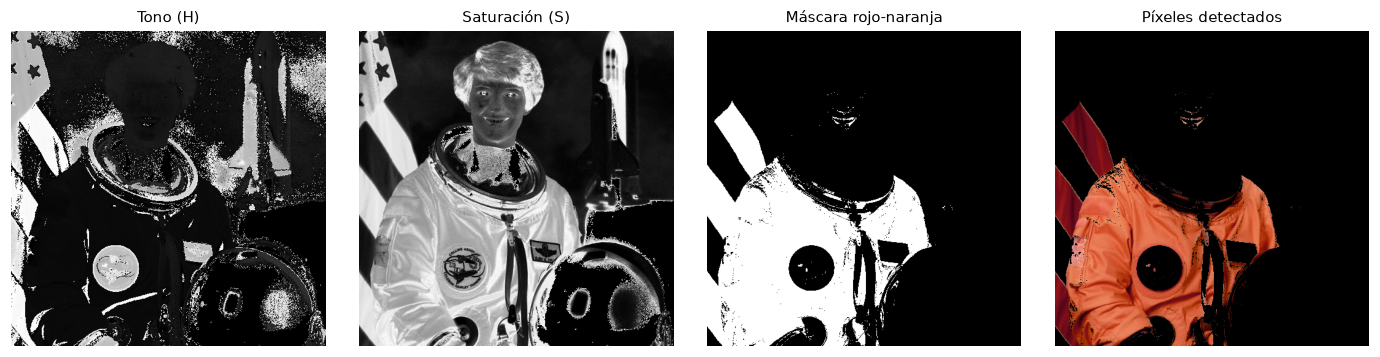

In [9]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(hsv)
# Máscara de tonos rojizos y anaranjados (el rojo está en ambos extremos del círculo de tono)
mascara = (((H < 10) | (H > 165)) & (S > 80) & (V > 50)).astype(np.uint8) * 255
resaltado = cv2.bitwise_and(rgb, rgb, mask=mascara)
mostrar([H, S, mascara, resaltado], ["Tono (H)", "Saturación (S)", "Máscara rojo-naranja", "Píxeles detectados"])

Pesos de OpenCV: Y = 0.299 R + 0.587 G + 0.114 B


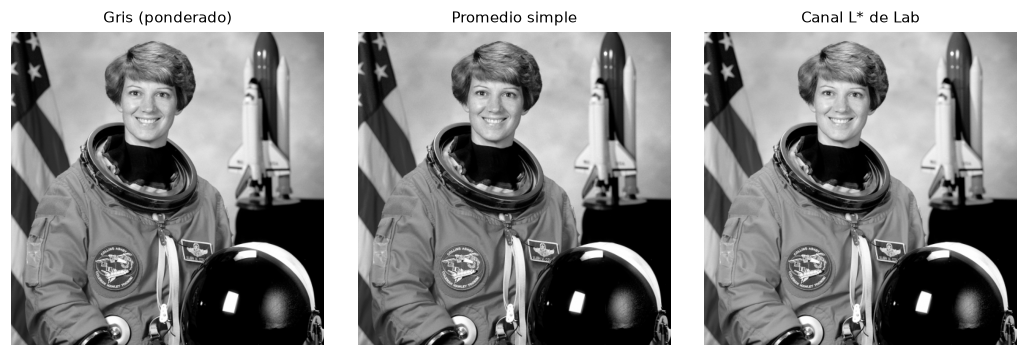

In [10]:
lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2Lab)
gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
# La conversión a gris NO es el promedio: pondera más el verde, al que el ojo es más sensible
gris_promedio = rgb.mean(axis=2).astype(np.uint8)
print("Pesos de OpenCV: Y = 0.299 R + 0.587 G + 0.114 B")
mostrar([gris, gris_promedio, lab[..., 0]], ["Gris (ponderado)", "Promedio simple", "Canal L* de Lab"])

🧪 **Experimenta.** Cambia los rangos de H para detectar los tonos azules (H ≈ 100–130) de la bandera, o sube el umbral de S y observa qué desaparece.

## 4. Tipo de dato y aritmética: el desbordamiento silencioso
Las imágenes suelen ser `uint8` (0–255). NumPy **da la vuelta** al pasarse de 255 (aritmética modular), mientras que OpenCV **satura**. Este error no lanza excepciones: solo produce imágenes incorrectas.

Píxel original: 201 | NumPy: 45 | OpenCV: 255


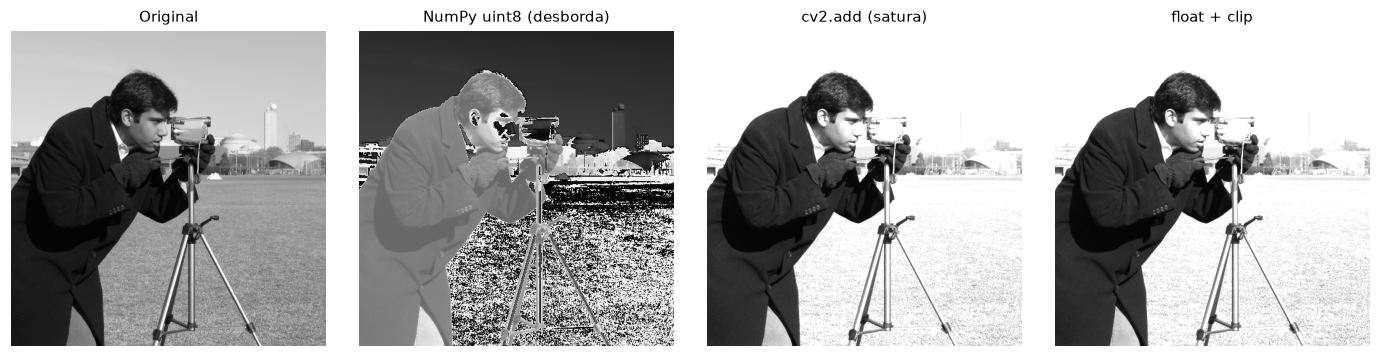

In [11]:
brillo = 100
numpy_suma = img + brillo                               # uint8: 250 + 100 = 94  (!)
opencv_suma = cv2.add(img, np.full_like(img, brillo))   # satura en 255
float_suma = np.clip(img.astype(np.float32) + brillo, 0, 255).astype(np.uint8)
print("Píxel original:", img[20, 20], "| NumPy:", numpy_suma[20, 20], "| OpenCV:", opencv_suma[20, 20])
mostrar([img, numpy_suma, opencv_suma, float_suma],
        ["Original", "NumPy uint8 (desborda)", "cv2.add (satura)", "float + clip"])

**Regla práctica:** convierte a `float32` en [0, 1] para operar (`skimage.util.img_as_float`) y vuelve a `uint8` solo para guardar o mostrar.

## 5. Formatos y compresión: ¿cuánto pierde un JPEG?
PNG comprime **sin pérdida**; JPEG **con pérdida** (controlada por la calidad). Medimos el error con el **error cuadrático medio (MSE)**:
$$\mathrm{MSE} = \frac{1}{MN}\sum_{x,y}\left(f(x,y) - \hat f(x,y)\right)^2$$

,Formato,Calidad,Tamaño (KB),MSE
0,PNG,-,454.02,0.00
1,JPEG,95,96.98,9.66
2,JPEG,50,27.10,40.44
3,JPEG,10,11.29,134.55
4,JPEG,2,6.25,442.26


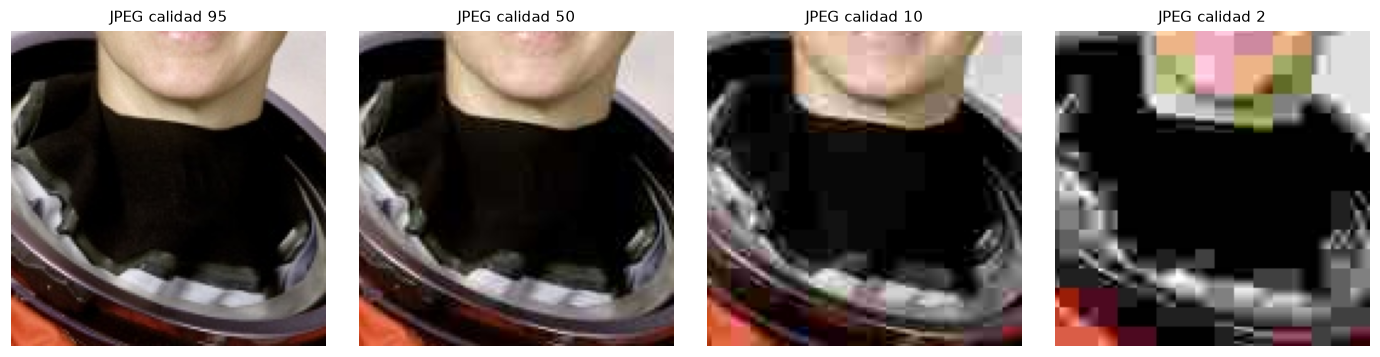

In [12]:
import os
import pandas as pd

def mse(a, b):
    return float(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2))

filas = []
bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite("prueba.png", bgr)
filas.append(("PNG", "-", os.path.getsize("prueba.png") / 1024, mse(bgr, cv2.imread("prueba.png"))))
reconstruidas = []
for q in [95, 50, 10, 2]:
    cv2.imwrite(f"prueba_q{q}.jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
    r = cv2.imread(f"prueba_q{q}.jpg")
    reconstruidas.append(cv2.cvtColor(r, cv2.COLOR_BGR2RGB)[150:280, 150:280])
    filas.append(("JPEG", q, os.path.getsize(f"prueba_q{q}.jpg") / 1024, mse(bgr, r)))
tabla = pd.DataFrame(filas, columns=["Formato", "Calidad", "Tamaño (KB)", "MSE"]).round(2)
display(tabla)
mostrar(reconstruidas, [f"JPEG calidad {q}" for q in [95, 50, 10, 2]])

💬 **Discusión.** Si vas a entrenar un modelo para detectar fisuras finas, ¿aceptarías imágenes JPEG de calidad 50? ¿Qué le pedirías al área que captura las imágenes?

## 6. Transformaciones geométricas básicas
Cambio de tamaño con distintas **interpolaciones**, rotación alrededor del centro, volteo y recorte.

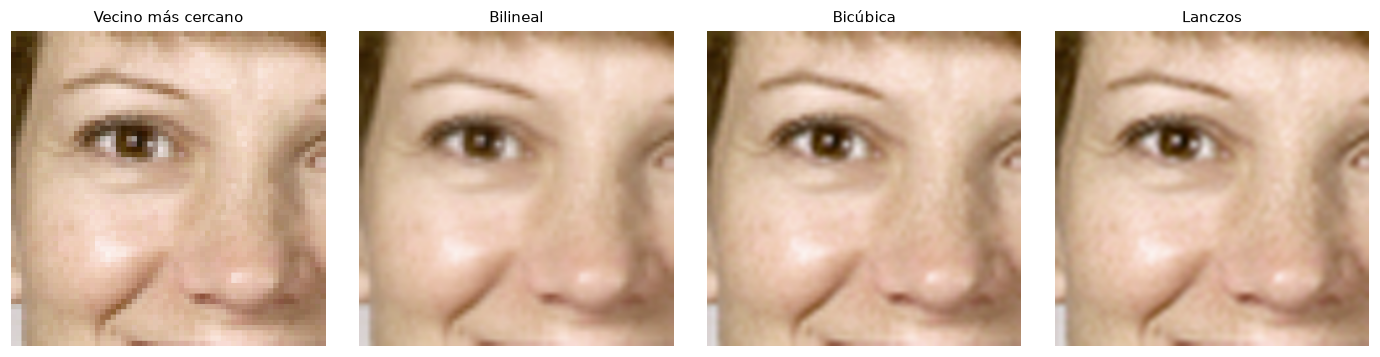

In [13]:
detalle = rgb[80:140, 180:240]
metodos = {"Vecino más cercano": cv2.INTER_NEAREST, "Bilineal": cv2.INTER_LINEAR,
           "Bicúbica": cv2.INTER_CUBIC, "Lanczos": cv2.INTER_LANCZOS4}
ampliadas = [cv2.resize(detalle, None, fx=6, fy=6, interpolation=m) for m in metodos.values()]
mostrar(ampliadas, list(metodos.keys()))

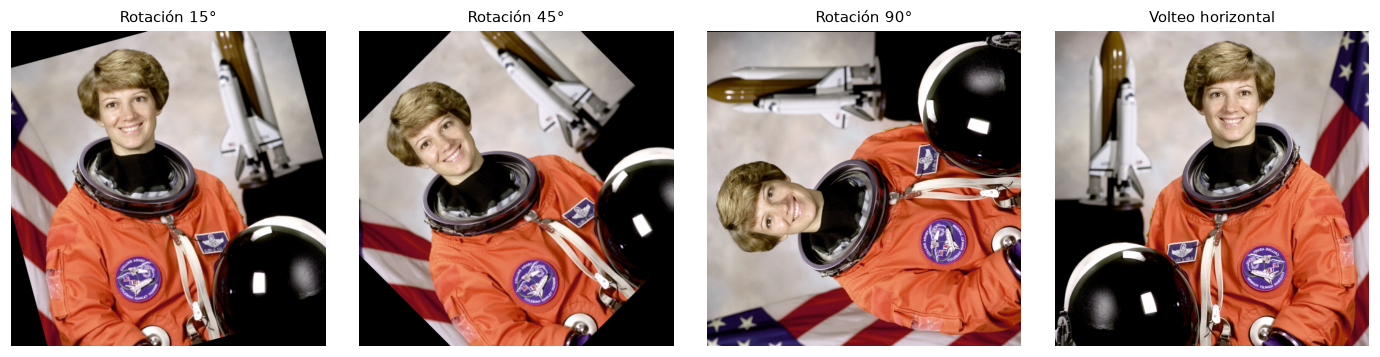

In [14]:
h, w = rgb.shape[:2]
rotadas = []
for ang in [15, 45, 90]:
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)   # centro, ángulo, escala
    rotadas.append(cv2.warpAffine(rgb, M, (w, h)))
volteada = cv2.flip(rgb, 1)                                   # 1 = horizontal, 0 = vertical
mostrar(rotadas + [volteada], ["Rotación 15°", "Rotación 45°", "Rotación 90°", "Volteo horizontal"])

## 7. Caso: las imágenes como conjunto de datos
En ciencia de datos rara vez analizamos *una* imagen: analizamos *colecciones*. `scikit-image` incluye 200 imágenes de 25 × 25 píxeles: 100 rostros (subconjunto de LFW) y 100 no-rostros. Con NumPy podemos calcular estadísticas **a nivel de conjunto**, como la imagen promedio de cada clase.

Forma del conjunto: (200, 25, 25)
Matriz de diseño: (200, 625)


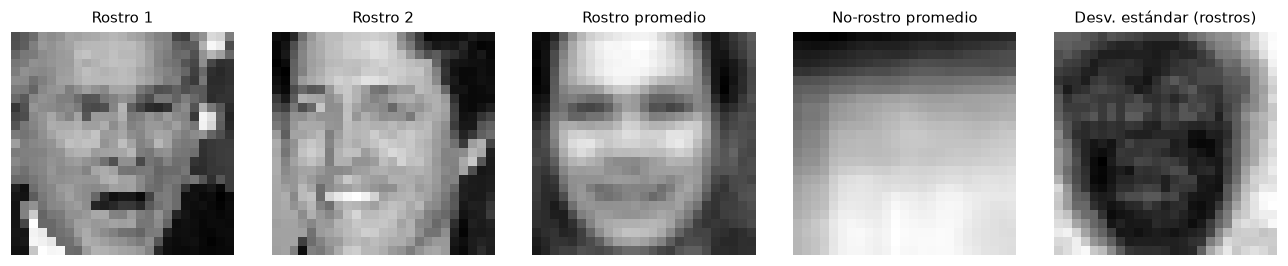

In [15]:
lfw = data.lfw_subset()           # arreglo (200, 25, 25) con valores en [0, 1]
rostros, no_rostros = lfw[:100], lfw[100:]
print("Forma del conjunto:", lfw.shape)
X = lfw.reshape(len(lfw), -1)     # cada imagen como un vector de 625 características
print("Matriz de diseño:", X.shape)
mostrar([rostros[0], rostros[1], rostros.mean(axis=0), no_rostros.mean(axis=0), rostros.std(axis=0)],
        ["Rostro 1", "Rostro 2", "Rostro promedio", "No-rostro promedio", "Desv. estándar (rostros)"], cols=5, tam=2.4)

Este reordenamiento —imagen → vector— es el puente entre el procesamiento de imágenes y el aprendizaje automático que recorreremos durante el curso. También abre preguntas éticas: los rostros son **datos personales sensibles**; usarlos exige consentimiento, propósito legítimo y protección (Ley Federal de Protección de Datos Personales en Posesión de los Particulares).

## 8. Resumen y conexión con la actividad 1A
| Concepto | Qué recordar |
|---|---|
| Imagen = arreglo | `forma = (alto, ancho[, canales])`, indexación `[fila, columna]` |
| Muestreo / cuantización | Resolución espacial vs. niveles de intensidad |
| Color | OpenCV usa **BGR**; HSV separa tono de brillo |
| Tipo de dato | `uint8` desborda; opera en `float` y recorta |
| Formatos | PNG sin pérdida, JPEG con pérdida (mide con MSE) |

**Actividad 1A. Introducción y manipulación básica de imágenes con OpenCV** (10 puntos, entrega: domingo 24 de enero de 2027). Usa la plantilla `1A_Plantilla_Manipulacion_basica.ipynb` y repite este recorrido **con tus propias imágenes**, interpretando cada resultado.